In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [4]:
df = pd.read_excel("../data/raw/Online Retail.xlsx")

print("Размер таблицы:", df.shape)
display(df.head())

Размер таблицы: (541909, 8)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[us]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  str           
dtypes: datetime64[us](1), float64(2), int64(1), object(3), str(1)
memory usage: 33.1+ MB


In [6]:
df.describe()

,Quantity,InvoiceDate,UnitPrice,CustomerID
count,541909.000000,541909,541909.000000,406829.000000
mean,9.552250,2011-07-04 13:34:57.156386,4.611114,15287.690570
min,-80995.000000,2010-12-01 08:26:00,-11062.060000,12346.000000
25%,1.000000,2011-03-28 11:34:00,1.250000,13953.000000
50%,3.000000,2011-07-19 17:17:00,2.080000,15152.000000
75%,10.000000,2011-10-19 11:27:00,4.130000,16791.000000
max,80995.000000,2011-12-09 12:50:00,38970.000000,18287.000000
std,218.081158,NaN,96.759853,1713.600303


In [7]:
df.isna().sum()

InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64

In [8]:
(df.isna().mean() * 100).round(2)

InvoiceNo       0.00
StockCode       0.00
Description     0.27
Quantity        0.00
InvoiceDate     0.00
UnitPrice       0.00
CustomerID     24.93
Country         0.00
dtype: float64

In [9]:
df.duplicated().sum()

np.int64(5268)

In [10]:
df[['Quantity', 'UnitPrice']].describe()

,Quantity,UnitPrice
count,541909.000000,541909.000000
mean,9.552250,4.611114
std,218.081158,96.759853
min,-80995.000000,-11062.060000
25%,1.000000,1.250000
50%,3.000000,2.080000
75%,10.000000,4.130000
max,80995.000000,38970.000000


In [11]:
df[df.duplicated(keep=False)].sort_values(
    by=["InvoiceNo", "StockCode"]
).head(10)

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
494,536409,21866,UNION JACK FLAG LUGGAGE TAG,1,2010-12-01 11:45:00,1.25,17908.0,United Kingdom
517,536409,21866,UNION JACK FLAG LUGGAGE TAG,1,2010-12-01 11:45:00,1.25,17908.0,United Kingdom
485,536409,22111,SCOTTIE DOG HOT WATER BOTTLE,1,2010-12-01 11:45:00,4.95,17908.0,United Kingdom
539,536409,22111,SCOTTIE DOG HOT WATER BOTTLE,1,2010-12-01 11:45:00,4.95,17908.0,United Kingdom
489,536409,22866,HAND WARMER SCOTTY DOG DESIGN,1,2010-12-01 11:45:00,2.10,17908.0,United Kingdom
527,536409,22866,HAND WARMER SCOTTY DOG DESIGN,1,2010-12-01 11:45:00,2.10,17908.0,United Kingdom
521,536409,22900,SET 2 TEA TOWELS I LOVE LONDON,1,2010-12-01 11:45:00,2.95,17908.0,United Kingdom
537,536409,22900,SET 2 TEA TOWELS I LOVE LONDON,1,2010-12-01 11:45:00,2.95,17908.0,United Kingdom
565,536412,21448,12 DAISY PEGS IN WOOD BOX,2,2010-12-01 11:49:00,1.65,17920.0,United Kingdom
578,536412,21448,12 DAISY PEGS IN WOOD BOX,1,2010-12-01 11:49:00,1.65,17920.0,United Kingdom


In [12]:
df.drop_duplicates().shape

(536641, 8)

In [13]:
df[df["Quantity"] < 0].head(10)

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
141,C536379,D,Discount,-1,2010-12-01 09:41:00,27.50,14527.0,United Kingdom
154,C536383,35004C,SET OF 3 COLOURED FLYING DUCKS,-1,2010-12-01 09:49:00,4.65,15311.0,United Kingdom
235,C536391,22556,PLASTERS IN TIN CIRCUS PARADE,-12,2010-12-01 10:24:00,1.65,17548.0,United Kingdom
236,C536391,21984,PACK OF 12 PINK PAISLEY TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0,United Kingdom
237,C536391,21983,PACK OF 12 BLUE PAISLEY TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0,United Kingdom
238,C536391,21980,PACK OF 12 RED RETROSPOT TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0,United Kingdom
239,C536391,21484,CHICK GREY HOT WATER BOTTLE,-12,2010-12-01 10:24:00,3.45,17548.0,United Kingdom
240,C536391,22557,PLASTERS IN TIN VINTAGE PAISLEY,-12,2010-12-01 10:24:00,1.65,17548.0,United Kingdom
241,C536391,22553,PLASTERS IN TIN SKULLS,-24,2010-12-01 10:24:00,1.65,17548.0,United Kingdom
939,C536506,22960,JAM MAKING SET WITH JARS,-6,2010-12-01 12:38:00,4.25,17897.0,United Kingdom


In [14]:
# Количество строк с отрицательными значениями
print("Quantity < 0:", (df["Quantity"] < 0).sum())
print("UnitPrice < 0:", (df["UnitPrice"] < 0).sum())

# Сколько операций имеют номера, начинающиеся с C
print(
    "Invoices starting with C:",
    df["InvoiceNo"].astype(str).str.startswith("C").sum()
)

# Примеры строк с отрицательной ценой
display(df[df["UnitPrice"] < 0].head(10))

Quantity < 0: 10624
UnitPrice < 0: 2
Invoices starting with C: 9288


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
299983,A563186,B,Adjust bad debt,1,2011-08-12 14:51:00,-11062.06,NaN,United Kingdom
299984,A563187,B,Adjust bad debt,1,2011-08-12 14:52:00,-11062.06,NaN,United Kingdom


In [15]:
# Создаём копию без полных дубликатов
df_clean = df.drop_duplicates().copy()

# Добавляем сумму строки
df_clean["LineAmount"] = (
    df_clean["Quantity"] * df_clean["UnitPrice"]
)

# Отмечаем особые операции
df_clean["IsCancellation"] = (
    df_clean["InvoiceNo"].astype(str).str.startswith("C")
)

df_clean["IsNegativeQuantity"] = df_clean["Quantity"] < 0

df_clean["IsNegativePrice"] = df_clean["UnitPrice"] < 0

print("Исходная таблица:", df.shape)
print("После удаления дубликатов:", df_clean.shape)
print("Строк с отрицательной ценой:", df_clean["IsNegativePrice"].sum())

Исходная таблица: (541909, 8)
После удаления дубликатов: (536641, 12)
Строк с отрицательной ценой: 2


In [16]:
df_sales = df_clean[
    (df_clean["Quantity"] > 0)
    & (df_clean["UnitPrice"] >= 0)
    & (~df_clean["IsCancellation"])
].copy()

print("Строк обычных продаж:", len(df_sales))
print("Выручка обычных продаж:", df_sales["LineAmount"].sum().round(2))
print("Количество заказов:", df_sales["InvoiceNo"].nunique())

Строк обычных продаж: 526052
Выручка обычных продаж: 10642110.8
Количество заказов: 20726


In [17]:
# Добавляем месяц заказа
df_sales["Month"] = (
    df_sales["InvoiceDate"].dt.to_period("M")
)

# Считаем месячные показатели
monthly_sales = (
    df_sales.groupby("Month")
    .agg(
        Revenue=("LineAmount", "sum"),
        Orders=("InvoiceNo", "nunique"),
        UnitsSold=("Quantity", "sum")
    )
    .reset_index()
)

monthly_sales["Revenue"] = monthly_sales["Revenue"].round(2)

monthly_sales["AverageOrderValue"] = (
    monthly_sales["Revenue"] / monthly_sales["Orders"]
).round(2)

display(monthly_sales)

,Month,Revenue,Orders,UnitsSold,AverageOrderValue
0,2010-12,821452.73,1629,361094,504.27
1,2011-01,689811.61,1120,397030,615.90
2,2011-02,522545.56,1126,286074,464.07
3,2011-03,716215.26,1531,384023,467.81
4,2011-04,536968.49,1318,311314,407.41
5,2011-05,769296.61,1731,398686,444.42
6,2011-06,760547.01,1576,393633,482.58
7,2011-07,718076.12,1540,405473,466.28
8,2011-08,757841.38,1407,424264,538.62
9,2011-09,1056435.19,1896,574169,557.19


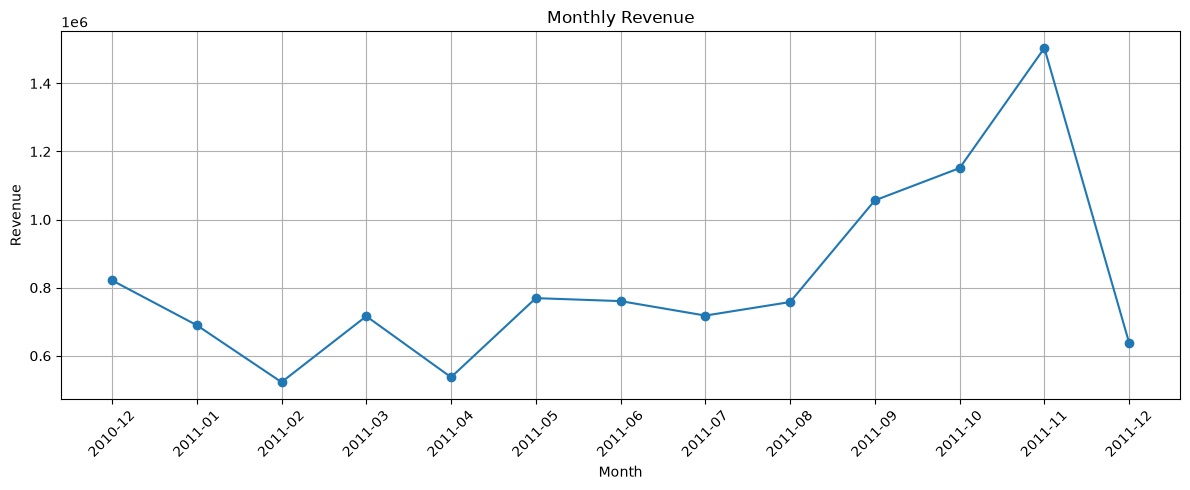

In [18]:
plt.figure(figsize=(12, 5))

plt.plot(
    monthly_sales["Month"].astype(str),
    monthly_sales["Revenue"],
    marker="o"
)

plt.title("Monthly Revenue")
plt.xlabel("Month")
plt.ylabel("Revenue")
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()

In [19]:
print("Первая дата:", df_sales["InvoiceDate"].min())
print("Последняя дата:", df_sales["InvoiceDate"].max())

Первая дата: 2010-12-01 08:26:00
Последняя дата: 2011-12-09 12:50:00


In [20]:
monthly_sales["RevenueChangePct"] = (
    monthly_sales["Revenue"].pct_change() * 100
).round(2)

display(monthly_sales)

,Month,Revenue,Orders,UnitsSold,AverageOrderValue,RevenueChangePct
0,2010-12,821452.73,1629,361094,504.27,NaN
1,2011-01,689811.61,1120,397030,615.90,-16.03
2,2011-02,522545.56,1126,286074,464.07,-24.25
3,2011-03,716215.26,1531,384023,467.81,37.06
4,2011-04,536968.49,1318,311314,407.41,-25.03
5,2011-05,769296.61,1731,398686,444.42,43.27
6,2011-06,760547.01,1576,393633,482.58,-1.14
7,2011-07,718076.12,1540,405473,466.28,-5.58
8,2011-08,757841.38,1407,424264,538.62,5.54
9,2011-09,1056435.19,1896,574169,557.19,39.40


In [21]:
feb_revenue = monthly_sales.loc[
    monthly_sales["Month"] == "2011-02", "Revenue"
].iloc[0]

nov_revenue = monthly_sales.loc[
    monthly_sales["Month"] == "2011-11", "Revenue"
].iloc[0]

growth_pct = (nov_revenue / feb_revenue - 1) * 100

print(f"Рост выручки с февраля по ноябрь: {growth_pct:.2f}%")

Рост выручки с февраля по ноябрь: 187.80%


In [22]:
print("Строк без CustomerID:", df_sales["CustomerID"].isna().sum())

print(
    "Уникальных клиентов:",
    df_sales["CustomerID"].nunique()
)

Строк без CustomerID: 133320
Уникальных клиентов: 4339


In [23]:
customer_stats = (
    df_sales.dropna(subset=["CustomerID"])
    .groupby("CustomerID")
    .agg(
        Orders=("InvoiceNo", "nunique"),
        Revenue=("LineAmount", "sum"),
        FirstPurchase=("InvoiceDate", "min"),
        LastPurchase=("InvoiceDate", "max")
    )
    .reset_index()
)

customer_stats.head()

,CustomerID,Orders,Revenue,FirstPurchase,LastPurchase
0,12346.0,1,77183.60,2011-01-18 10:01:00,2011-01-18 10:01:00
1,12347.0,7,4310.00,2010-12-07 14:57:00,2011-12-07 15:52:00
2,12348.0,4,1797.24,2010-12-16 19:09:00,2011-09-25 13:13:00
3,12349.0,1,1757.55,2011-11-21 09:51:00,2011-11-21 09:51:00
4,12350.0,1,334.40,2011-02-02 16:01:00,2011-02-02 16:01:00


In [24]:
# Классифицируем клиентов по числу заказов
customer_stats["CustomerType"] = np.where(
    customer_stats["Orders"] > 1,
    "Repeat",
    "One-time"
)

# Сводка по типам клиентов
customer_summary = (
    customer_stats.groupby("CustomerType")
    .agg(
        Customers=("CustomerID", "nunique"),
        Revenue=("Revenue", "sum"),
        AvgRevenuePerCustomer=("Revenue", "mean"),
        AvgOrders=("Orders", "mean")
    )
    .reset_index()
)

customer_summary["CustomerSharePct"] = (
    customer_summary["Customers"]
    / customer_summary["Customers"].sum() * 100
).round(2)

customer_summary["RevenueSharePct"] = (
    customer_summary["Revenue"]
    / customer_summary["Revenue"].sum() * 100
).round(2)

display(customer_summary.round(2))

,CustomerType,Customers,Revenue,AvgRevenuePerCustomer,AvgOrders,CustomerSharePct,RevenueSharePct
0,One-time,1494,613989.56,410.97,1.00,34.43,6.91
1,Repeat,2845,8273219.33,2907.99,5.99,65.57,93.09


In [25]:
# Сортируем клиентов по выручке
top_customers = customer_stats.sort_values(
    "Revenue", ascending=False
).copy()

# Доля каждого клиента в выручке идентифицированных клиентов
total_customer_revenue = top_customers["Revenue"].sum()

top_customers["RevenueSharePct"] = (
    top_customers["Revenue"]
    / total_customer_revenue * 100
)

# Накопительная доля выручки
top_customers["CumulativeRevenueSharePct"] = (
    top_customers["RevenueSharePct"].cumsum()
)

display(top_customers.head(10).round(2))

/var/folders/0f/vqjdc3bx7dv01nhfpk81tl9h0000gn/T/ipykernel_65255/3732881622.py:19: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(top_customers.head(10).round(2))


,CustomerID,Orders,Revenue,FirstPurchase,LastPurchase,CustomerType,RevenueSharePct,CumulativeRevenueSharePct
1690,14646.0,74,280206.02,2010-12-20 10:09:00,2011-12-08 12:12:00,Repeat,3.15,3.15
4202,18102.0,60,259657.30,2010-12-07 16:42:00,2011-12-09 11:50:00,Repeat,2.92,6.07
3729,17450.0,46,194390.79,2010-12-07 09:23:00,2011-12-01 13:29:00,Repeat,2.19,8.26
3009,16446.0,2,168472.50,2011-05-18 09:52:00,2011-12-09 09:15:00,Repeat,1.90,10.16
1880,14911.0,201,143711.17,2010-12-01 14:05:00,2011-12-08 15:54:00,Repeat,1.62,11.77
55,12415.0,21,124914.53,2011-01-06 11:12:00,2011-11-15 14:22:00,Repeat,1.41,13.18
1334,14156.0,55,117210.08,2010-12-03 11:48:00,2011-11-30 10:54:00,Repeat,1.32,14.50
3772,17511.0,31,91062.38,2010-12-01 10:19:00,2011-12-07 10:12:00,Repeat,1.02,15.52
2703,16029.0,63,80850.84,2010-12-01 09:57:00,2011-11-01 10:27:00,Repeat,0.91,16.43
0,12346.0,1,77183.60,2011-01-18 10:01:00,2011-01-18 10:01:00,One-time,0.87,17.30


In [26]:
top10_share = (
    top_customers.head(10)["Revenue"].sum()
    / total_customer_revenue * 100
)

print(f"Доля топ-10 клиентов в выручке: {top10_share:.2f}%")

Доля топ-10 клиентов в выручке: 17.30%


In [27]:
print(
    "Средняя выручка на клиента:",
    round(customer_stats["Revenue"].mean(), 2)
)

print(
    "Медианная выручка на клиента:",
    round(customer_stats["Revenue"].median(), 2)
)

Средняя выручка на клиента: 2048.22
Медианная выручка на клиента: 668.56


In [28]:
product_stats = (
    df_sales.dropna(subset=["Description"])
    .groupby(["StockCode", "Description"])
    .agg(
        Revenue=("LineAmount", "sum"),
        UnitsSold=("Quantity", "sum"),
        Orders=("InvoiceNo", "nunique")
    )
    .reset_index()
)

product_stats = product_stats.sort_values(
    "Revenue", ascending=False
)

display(product_stats.head(10).round(2))

,StockCode,Description,Revenue,UnitsSold,Orders
4307,DOT,DOTCOM POSTAGE,206248.77,708,708
1315,22423,REGENCY CAKESTAND 3 TIER,174156.54,13862,1989
2687,23843,"PAPER CRAFT , LITTLE BIRDIE",168469.60,80995,1
3925,85123A,WHITE HANGING HEART T-LIGHT HOLDER,104284.24,37584,2193
2772,47566,PARTY BUNTING,99445.23,18287,1686
3912,85099B,JUMBO BAG RED RETROSPOT,94159.81,48375,2092
2131,23166,MEDIUM CERAMIC TOP STORAGE JAR,81700.92,78033,247
4310,POST,POSTAGE,78101.88,3150,1126
4308,M,Manual,77750.27,6990,294
2028,23084,RABBIT NIGHT LIGHT,66870.03,30739,994


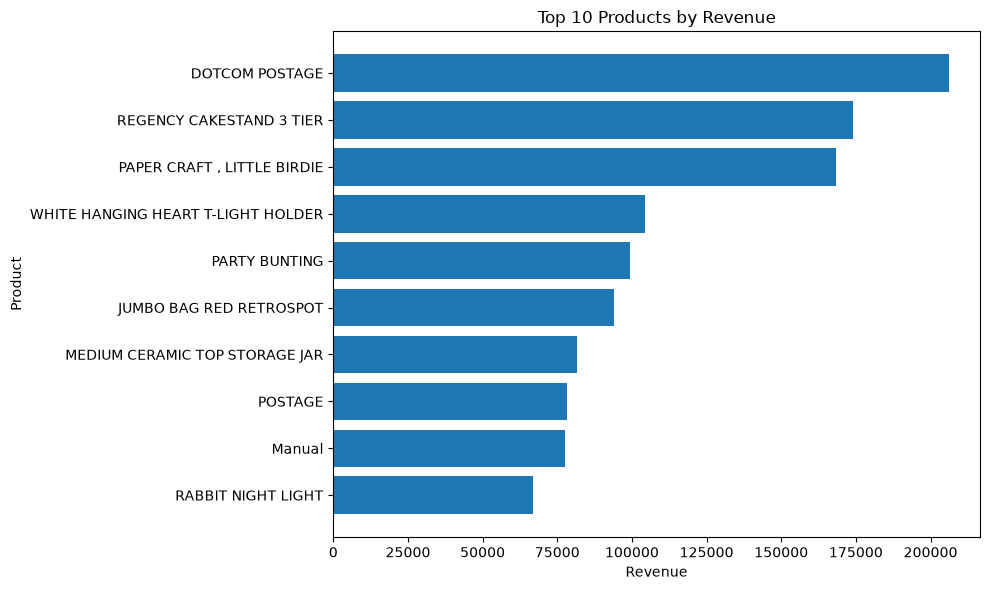

In [29]:
top_products = product_stats.head(10).sort_values("Revenue")

plt.figure(figsize=(10, 6))

plt.barh(
    top_products["Description"],
    top_products["Revenue"]
)

plt.title("Top 10 Products by Revenue")
plt.xlabel("Revenue")
plt.ylabel("Product")
plt.tight_layout()
plt.show()

In [30]:
# Посмотрим на служебные позиции с высокой выручкой
display(
    product_stats[
        product_stats["Description"].str.contains(
            "POSTAGE|DOTCOM|MANUAL|ADJUST|DISCOUNT",
            case=False,
            na=False
        )
    ].sort_values("Revenue", ascending=False).head(20)
)

,StockCode,Description,Revenue,UnitsSold,Orders
4307,DOT,DOTCOM POSTAGE,206248.77,708,708
4310,POST,POSTAGE,78101.88,3150,1126
4308,M,Manual,77750.27,6990,294
4297,B,Adjust bad debt,11062.06,1,1
4315,gift_0001_30,Dotcomgiftshop Gift Voucher £30.00,175.53,7,7
4317,gift_0001_50,Dotcomgiftshop Gift Voucher £50.00,167.56,4,4
4313,gift_0001_20,Dotcomgiftshop Gift Voucher £20.00,167.05,10,9
4316,gift_0001_40,Dotcomgiftshop Gift Voucher £40.00,100.70,3,3
926,22016,Dotcomgiftshop Gift Voucher £100.00,83.33,1,1
4312,gift_0001_10,Dotcomgiftshop Gift Voucher £10.00,74.97,9,8


In [31]:
excluded_patterns = (
    "POSTAGE|DOTCOM|MANUAL|ADJUST|DISCOUNT"
)

regular_products = product_stats[
    ~product_stats["Description"].str.contains(
        excluded_patterns,
        case=False,
        na=False
    )
].copy()

display(regular_products.head(10).round(2))

,StockCode,Description,Revenue,UnitsSold,Orders
1315,22423,REGENCY CAKESTAND 3 TIER,174156.54,13862,1989
2687,23843,"PAPER CRAFT , LITTLE BIRDIE",168469.60,80995,1
3925,85123A,WHITE HANGING HEART T-LIGHT HOLDER,104284.24,37584,2193
2772,47566,PARTY BUNTING,99445.23,18287,1686
3912,85099B,JUMBO BAG RED RETROSPOT,94159.81,48375,2092
2131,23166,MEDIUM CERAMIC TOP STORAGE JAR,81700.92,78033,247
2028,23084,RABBIT NIGHT LIGHT,66870.03,30739,994
988,22086,PAPER CHAIN KIT 50'S CHRISTMAS,64875.59,19329,1160
2985,84879,ASSORTED COLOUR BIRD ORNAMENT,58927.62,36362,1455
2843,79321,CHILLI LIGHTS,54096.36,10305,663


In [32]:
total_product_revenue = regular_products["Revenue"].sum()

top10_product_share = (
    regular_products.head(10)["Revenue"].sum()
    / total_product_revenue * 100
)

print(
    f"Доля топ-10 товаров в выручке обычных товаров: "
    f"{top10_product_share:.2f}%"
)

Доля топ-10 товаров в выручке обычных товаров: 9.42%


In [33]:
top_products_by_orders = regular_products.sort_values(
    "Orders", ascending=False
).head(10)

display(top_products_by_orders.round(2))

,StockCode,Description,Revenue,UnitsSold,Orders
3925,85123A,WHITE HANGING HEART T-LIGHT HOLDER,104284.24,37584,2193
3912,85099B,JUMBO BAG RED RETROSPOT,94159.81,48375,2092
1315,22423,REGENCY CAKESTAND 3 TIER,174156.54,13862,1989
2772,47566,PARTY BUNTING,99445.23,18287,1686
108,20725,LUNCH BAG RED RETROSPOT,35572.36,19232,1564
2985,84879,ASSORTED COLOUR BIRD ORNAMENT,58927.62,36362,1455
1613,22720,SET OF 3 CAKE TINS PANTRY DESIGN,38108.89,7483,1385
391,21212,PACK OF 72 RETROSPOT CAKE CASES,21246.45,36396,1320
111,20727,LUNCH BAG BLACK SKULL.,22346.96,12195,1273
1348,22457,NATURAL SLATE HEART CHALKBOARD,27991.61,9119,1249


In [34]:
top_products_by_units = regular_products.sort_values(
    "UnitsSold", ascending=False
).head(10)

display(top_products_by_units.round(2))

,StockCode,Description,Revenue,UnitsSold,Orders
2687,23843,"PAPER CRAFT , LITTLE BIRDIE",168469.60,80995,1
2131,23166,MEDIUM CERAMIC TOP STORAGE JAR,81700.92,78033,247
2879,84077,WORLD WAR 2 GLIDERS ASSTD DESIGNS,13814.01,54951,535
3912,85099B,JUMBO BAG RED RETROSPOT,94159.81,48375,2092
3925,85123A,WHITE HANGING HEART T-LIGHT HOLDER,104284.24,37584,2193
1103,22197,POPCORN HOLDER,34288.67,36749,803
391,21212,PACK OF 72 RETROSPOT CAKE CASES,21246.45,36396,1320
2985,84879,ASSORTED COLOUR BIRD ORNAMENT,58927.62,36362,1455
2028,23084,RABBIT NIGHT LIGHT,66870.03,30739,994
1381,22492,MINI PAINT SET VINTAGE,16937.82,26633,380


In [35]:
df_sales[
    df_sales["StockCode"] == "23843"
][[
    "InvoiceNo",
    "InvoiceDate",
    "CustomerID",
    "Country",
    "Quantity",
    "UnitPrice",
    "LineAmount"
]]

,InvoiceNo,InvoiceDate,CustomerID,Country,Quantity,UnitPrice,LineAmount


In [36]:
print(df_sales["StockCode"].dtype)

print(
    df_sales[df_sales["StockCode"].astype(str).str.strip() == "23843"][
        ["InvoiceNo", "InvoiceDate", "CustomerID", "Country",
         "Quantity", "UnitPrice", "LineAmount"]
    ].to_string(index=False)
)

object
InvoiceNo         InvoiceDate  CustomerID        Country  Quantity  UnitPrice  LineAmount
   581483 2011-12-09 09:15:00     16446.0 United Kingdom     80995       2.08    168469.6


In [37]:
total_revenue = df_sales["LineAmount"].sum()

product_revenue = df_sales.loc[
    df_sales["StockCode"] == "23843",
    "LineAmount"
].sum()

print(f"Общая выручка: {total_revenue:,.2f}")
print(f"Выручка от товара: {product_revenue:,.2f}")
print(f"Доля в общей выручке: {product_revenue / total_revenue * 100:.2f}%")

Общая выручка: 10,642,110.80
Выручка от товара: 0.00
Доля в общей выручке: 0.00%


In [38]:
df_sales.loc[
    df_sales["Description"].str.contains(
        "PAPER CRAFT", case=False, na=False
    ),
    ["StockCode", "Description", "Quantity", "LineAmount"]
].head()

,StockCode,Description,Quantity,LineAmount
540421,23843,"PAPER CRAFT , LITTLE BIRDIE",80995,168469.6


In [39]:
mask = df_sales["StockCode"].astype(str).str.strip() == "23843"

product_revenue = df_sales.loc[mask, "LineAmount"].sum()
total_revenue = df_sales["LineAmount"].sum()

print(f"Строк найдено: {mask.sum()}")
print(f"Выручка от товара: {product_revenue:,.2f}")
print(f"Доля в общей выручке: {product_revenue / total_revenue * 100:.2f}%")

Строк найдено: 1
Выручка от товара: 168,469.60
Доля в общей выручке: 1.58%


In [40]:
df_sales.loc[
    df_sales["InvoiceNo"].astype(str) == "581483",
    ["StockCode", "Description", "Quantity", "UnitPrice", "LineAmount"]
]

,StockCode,Description,Quantity,UnitPrice,LineAmount
540421,23843,"PAPER CRAFT , LITTLE BIRDIE",80995,2.08,168469.6


In [41]:
order_stats = (
    df_sales.groupby("InvoiceNo")
    .agg(
        Revenue=("LineAmount", "sum"),
        UnitsSold=("Quantity", "sum"),
        UniqueProducts=("StockCode", "nunique")
    )
    .reset_index()
)

display(
    order_stats.sort_values("Revenue", ascending=False).head(10)
)

,InvoiceNo,Revenue,UnitsSold,UniqueProducts
20689,581483,168469.60,80995,1
2202,541431,77183.60,74215,1
17582,574941,52940.94,14149,101
18251,576365,50653.91,13956,99
9034,556444,38970.00,60,1
14071,567423,31698.16,12572,12
9240,556917,22775.93,15049,138
16293,572209,22206.00,1920,7
14063,567381,22104.80,6760,12
12335,563614,21880.44,12196,97


In [42]:
df_sales.loc[
    df_sales["InvoiceNo"].astype(str) == "541431",
    [
        "InvoiceNo",
        "InvoiceDate",
        "CustomerID",
        "Country",
        "StockCode",
        "Description",
        "Quantity",
        "UnitPrice",
        "LineAmount"
    ]
]

,InvoiceNo,InvoiceDate,CustomerID,Country,StockCode,Description,Quantity,UnitPrice,LineAmount
61619,541431,2011-01-18 10:01:00,12346.0,United Kingdom,23166,MEDIUM CERAMIC TOP STORAGE JAR,74215,1.04,77183.6


In [43]:
df[
    df["StockCode"].astype(str).str.strip().isin(["23843", "23166"])
    & df["InvoiceNo"].astype(str).str.startswith("C")
][
    ["InvoiceNo", "InvoiceDate", "CustomerID", "StockCode",
     "Description", "Quantity", "UnitPrice"]
].sort_values("InvoiceDate")

,InvoiceNo,InvoiceDate,CustomerID,StockCode,Description,Quantity,UnitPrice
61624,C541433,2011-01-18 10:17:00,12346.0,23166,MEDIUM CERAMIC TOP STORAGE JAR,-74215,1.04
203625,C554527,2011-05-24 17:25:00,15251.0,23166,MEDIUM CERAMIC TOP STORAGE JAR,-9,1.04
234364,C557508,2011-06-20 16:13:00,16684.0,23166,MEDIUM CERAMIC TOP STORAGE JAR,-240,1.04
270084,C560540,2011-07-19 12:26:00,12415.0,23166,MEDIUM CERAMIC TOP STORAGE JAR,-1,1.25
290357,C562375,2011-08-04 14:46:00,14911.0,23166,MEDIUM CERAMIC TOP STORAGE JAR,-12,1.25
297530,C562952,2011-08-11 10:10:00,12749.0,23166,MEDIUM CERAMIC TOP STORAGE JAR,-1,1.25
349848,C567535,2011-09-21 09:50:00,15253.0,23166,MEDIUM CERAMIC TOP STORAGE JAR,-1,1.25
352712,C567677,2011-09-21 15:57:00,12409.0,23166,MEDIUM CERAMIC TOP STORAGE JAR,-2,1.04
394002,C570867,2011-10-12 16:17:00,12607.0,23166,MEDIUM CERAMIC TOP STORAGE JAR,-12,1.25
421501,C572991,2011-10-27 10:56:00,17672.0,23166,MEDIUM CERAMIC TOP STORAGE JAR,-1,1.25


In [44]:
df_net = df_clean[
    (df_clean["UnitPrice"] >= 0)
].copy()

net_revenue = df_net["LineAmount"].sum()

print(f"Выручка с учётом строк отмен: {net_revenue:,.2f}")
print(f"Выручка без учёта отмен: {df_sales['LineAmount'].sum():,.2f}")

Выручка с учётом строк отмен: 9,748,131.07
Выручка без учёта отмен: 10,642,110.80


In [45]:
cancellations = df_clean[
    df_clean["InvoiceNo"].astype(str).str.startswith("C")
].copy()

print("Количество строк отмен:", len(cancellations))
print("Количество отменённых счетов:", cancellations["InvoiceNo"].nunique())
print("Сумма строк отмен:", cancellations["LineAmount"].sum())

Количество строк отмен: 9251
Количество отменённых счетов: 3836
Сумма строк отмен: -893979.73


In [46]:
cancelled_invoices = cancellations["InvoiceNo"].astype(str).str[1:].unique()

df_without_cancelled_orders = df_net[
    ~df_net["InvoiceNo"].astype(str).isin(cancelled_invoices)
].copy()

print(
    "Выручка без отменённых заказов:",
    round(df_without_cancelled_orders["LineAmount"].sum(), 2)
)

Выручка без отменённых заказов: 9748131.07


In [47]:
print(
    "Заказов до исключения отмен:",
    df_net["InvoiceNo"].nunique()
)

print(
    "Заказов после исключения отмен:",
    df_without_cancelled_orders["InvoiceNo"].nunique()
)

Заказов до исключения отмен: 25898
Заказов после исключения отмен: 25898


In [48]:
# Номера отмен без буквы C
cancelled_original_ids = set(
    cancellations["InvoiceNo"].astype(str).str[1:]
)

# Все номера заказов без префикса C
invoice_ids = df_net["InvoiceNo"].astype(str)

# Считаем исходные заказы, для которых есть отмена
original_orders = invoice_ids[
    invoice_ids.isin(cancelled_original_ids)
].nunique()

print("Исходных заказов с отменой:", original_orders)
print("Всего счетов в df_net:", df_net["InvoiceNo"].nunique())

Исходных заказов с отменой: 0
Всего счетов в df_net: 25898


In [49]:
print(
    "Строк с отрицательным количеством:",
    (df_clean["Quantity"] < 0).sum()
)

print(
    "Строк с отрицательным количеством и без C в InvoiceNo:",
    (
        (df_clean["Quantity"] < 0)
        & ~df_clean["InvoiceNo"].astype(str).str.startswith("C")
    ).sum()
)

Строк с отрицательным количеством: 10587
Строк с отрицательным количеством и без C в InvoiceNo: 1336


In [50]:
df_clean[
    (df_clean["Quantity"] < 0)
    & ~df_clean["InvoiceNo"].astype(str).str.startswith("C")
][
    ["InvoiceNo", "InvoiceDate", "CustomerID", "StockCode",
     "Description", "Quantity", "UnitPrice", "LineAmount"]
].head(15)

,InvoiceNo,InvoiceDate,CustomerID,StockCode,Description,Quantity,UnitPrice,LineAmount
2406,536589,2010-12-01 16:50:00,NaN,21777,NaN,-10,0.0,-0.0
4347,536764,2010-12-02 14:42:00,NaN,84952C,NaN,-38,0.0,-0.0
7188,536996,2010-12-03 15:30:00,NaN,22712,NaN,-20,0.0,-0.0
7189,536997,2010-12-03 15:30:00,NaN,22028,NaN,-20,0.0,-0.0
7190,536998,2010-12-03 15:30:00,NaN,85067,NaN,-6,0.0,-0.0
7192,537000,2010-12-03 15:32:00,NaN,21414,NaN,-22,0.0,-0.0
7193,537001,2010-12-03 15:33:00,NaN,21653,NaN,-6,0.0,-0.0
7195,537003,2010-12-03 15:33:00,NaN,85126,NaN,-2,0.0,-0.0
7196,537004,2010-12-03 15:34:00,NaN,21814,NaN,-30,0.0,-0.0
7197,537005,2010-12-03 15:35:00,NaN,21692,NaN,-70,0.0,-0.0


In [51]:
negative_without_c = df_clean[
    (df_clean["Quantity"] < 0)
    & ~df_clean["InvoiceNo"].astype(str).str.startswith("C")
].copy()

print("Всего строк:", len(negative_without_c))
print(
    "Строк с нулевой ценой:",
    (negative_without_c["UnitPrice"] == 0).sum()
)
print(
    "Строк без описания:",
    negative_without_c["Description"].isna().sum()
)
print(
    "Строк без CustomerID:",
    negative_without_c["CustomerID"].isna().sum()
)
print(
    "Суммарная стоимость строк:",
    round(negative_without_c["LineAmount"].sum(), 2)
)

Всего строк: 1336
Строк с нулевой ценой: 1336
Строк без описания: 862
Строк без CustomerID: 1336
Суммарная стоимость строк: 0.0


In [52]:
df_sales_final = df_clean[
    (~df_clean["InvoiceNo"].astype(str).str.startswith("C"))
    & (df_clean["Quantity"] > 0)
    & (df_clean["UnitPrice"] >= 0)
].copy()

print("Строк продаж:", len(df_sales_final))
print("Уникальных счетов:", df_sales_final["InvoiceNo"].nunique())
print(
    "Выручка:",
    round((df_sales_final["Quantity"] * df_sales_final["UnitPrice"]).sum(), 2)
)

Строк продаж: 526052
Уникальных счетов: 20726
Выручка: 10642110.8


In [53]:
print("Отрицательное количество:", (df_sales_final["Quantity"] < 0).sum())
print("Отрицательная цена:", (df_sales_final["UnitPrice"] < 0).sum())
print(
    "Счета с префиксом C:",
    df_sales_final["InvoiceNo"].astype(str).str.startswith("C").sum()
)
print("Пропуски CustomerID:", df_sales_final["CustomerID"].isna().sum())

Отрицательное количество: 0
Отрицательная цена: 0
Счета с префиксом C: 0
Пропуски CustomerID: 133320


In [54]:
# Основные показатели
total_revenue = (
    df_sales_final["Quantity"] * df_sales_final["UnitPrice"]
).sum()

total_orders = df_sales_final["InvoiceNo"].nunique()
total_units = df_sales_final["Quantity"].sum()

print(f"Выручка: {total_revenue:,.2f}")
print(f"Количество заказов: {total_orders:,}")
print(f"Продано единиц: {total_units:,}")
print(f"Средняя сумма заказа: {total_revenue / total_orders:,.2f}")

Выручка: 10,642,110.80
Количество заказов: 20,726
Продано единиц: 5,645,017
Средняя сумма заказа: 513.47


In [55]:
country_stats = (
    df_sales_final.groupby("Country")
    .agg(
        Revenue=("LineAmount", "sum"),
        Orders=("InvoiceNo", "nunique"),
        UnitsSold=("Quantity", "sum")
    )
    .reset_index()
    .sort_values("Revenue", ascending=False)
)

country_stats["RevenueSharePct"] = (
    country_stats["Revenue"] / country_stats["Revenue"].sum() * 100
)

display(country_stats.head(10).round(2))

,Country,Revenue,Orders,UnitsSold,RevenueSharePct
36,United Kingdom,9001744.09,18784,4718327,84.59
24,Netherlands,285446.34,95,200937,2.68
10,EIRE,283140.52,288,147281,2.66
14,Germany,228678.40,457,119156,2.15
13,France,209625.37,392,112061,1.97
0,Australia,138453.81,57,84199,1.30
31,Spain,61558.56,90,27944,0.58
33,Switzerland,57067.60,54,30618,0.54
3,Belgium,41196.34,98,23237,0.39
32,Sweden,38367.83,36,36078,0.36


In [56]:
df_sales_final["LineAmount"] = (
    df_sales_final["Quantity"] * df_sales_final["UnitPrice"]
)

In [57]:
country_stats["AverageOrderValue"] = (
    country_stats["Revenue"] / country_stats["Orders"]
)

display(
    country_stats.sort_values(
        "AverageOrderValue", ascending=False
    ).head(10).round(2)
)

,Country,Revenue,Orders,UnitsSold,RevenueSharePct,AverageOrderValue
30,Singapore,21279.29,7,5241,0.20,3039.90
24,Netherlands,285446.34,95,200937,2.68,3004.70
0,Australia,138453.81,57,84199,1.30,2429.01
20,Japan,37416.37,19,26016,0.35,1969.28
21,Lebanon,1693.88,1,386,0.02,1693.88
16,Hong Kong,15483.00,11,4713,0.15,1407.55
4,Brazil,1143.60,1,356,0.01,1143.60
32,Sweden,38367.83,36,36078,0.36,1065.77
33,Switzerland,57067.60,54,30618,0.54,1056.81
9,Denmark,18955.34,18,8235,0.18,1053.07


In [58]:
country_stats_30 = country_stats[
    country_stats["Orders"] >= 30
].copy()

display(
    country_stats_30.sort_values(
        "AverageOrderValue", ascending=False
    ).head(10).round(2)
)

,Country,Revenue,Orders,UnitsSold,RevenueSharePct,AverageOrderValue
24,Netherlands,285446.34,95,200937,2.68,3004.70
0,Australia,138453.81,57,84199,1.30,2429.01
32,Sweden,38367.83,36,36078,0.36,1065.77
33,Switzerland,57067.60,54,30618,0.54,1056.81
25,Norway,36165.44,36,19338,0.34,1004.60
10,EIRE,283140.52,288,147281,2.66,983.13
31,Spain,61558.56,90,27944,0.58,683.98
27,Portugal,33683.05,58,16231,0.32,580.74
12,Finland,22546.08,41,10704,0.21,549.90
13,France,209625.37,392,112061,1.97,534.76


In [59]:
top5_share = country_stats.head(5)["Revenue"].sum() / country_stats["Revenue"].sum() * 100

print(f"Доля топ-5 стран в выручке: {top5_share:.2f}%")

Доля топ-5 стран в выручке: 94.05%
